# Практическая работа №2 «Создание конкурентной нейронной сети»

**Выполнил:** Федотов Георгий Николаевич, ИТ-23Д  
**Вариант №37:** S, Z, 2, 5, 8

**Цель работы:** изучить топологию и алгоритм функционирования конкурентной нейронной сети.


## 1. Исходные образы 6×6

Зададим растровые изображения символов своего варианта. Здесь 1 обозначает чёрную клетку, 0 — белый фон. Фиксируем seed=37 для повторяемости.


In [13]:
import numpy as np
import matplotlib.pyplot as plt
import math

np.random.seed(37)

S = np.array([
    [0, 1, 1, 1, 1, 0],
    [1, 1, 0, 0, 0, 0],
    [0, 1, 1, 1, 1, 0],
    [0, 0, 0, 0, 1, 1],
    [1, 0, 0, 0, 1, 1],
    [0, 1, 1, 1, 1, 0]
], dtype=float)
Z = np.array([
    [1, 1, 1, 1, 1, 1],
    [0, 0, 0, 0, 1, 0],
    [0, 0, 0, 1, 0, 0],
    [0, 0, 1, 0, 0, 0],
    [0, 1, 0, 0, 0, 0],
    [1, 1, 1, 1, 1, 1]
], dtype=float)
TWO = np.array([
    [0, 1, 1, 1, 1, 0],
    [1, 0, 0, 0, 1, 1],
    [0, 0, 0, 0, 1, 1],
    [0, 0, 1, 1, 1, 0],
    [0, 1, 1, 0, 0, 0],
    [1, 1, 1, 1, 1, 1]
], dtype=float)
FIVE = np.array([
    [1, 1, 1, 1, 1, 1],
    [1, 0, 0, 0, 0, 0],
    [1, 1, 1, 1, 1, 0],
    [0, 0, 0, 0, 1, 1],
    [1, 0, 0, 0, 1, 1],
    [0, 1, 1, 1, 1, 0]
], dtype=float)
EIGHT = np.array([
    [0, 1, 1, 1, 1, 0],
    [1, 1, 0, 0, 1, 1],
    [0, 1, 1, 1, 1, 0],
    [1, 1, 0, 0, 1, 1],
    [1, 1, 0, 0, 1, 1],
    [0, 1, 1, 1, 1, 0]
], dtype=float)

base_images = {'S': S, 'Z': Z, '2': TWO, '5': FIVE, '8': EIGHT}
assert all(img.shape == (6, 6) for img in base_images.values())
assert all(np.isin(img, [0, 1]).all() for img in base_images.values())
print('Вариант 37: S, Z, 2, 5, 8. Размер каждого образа: 6×6.')


Вариант 37: S, Z, 2, 5, 8. Размер каждого образа: 6×6.


## 2. Вспомогательные функции

`img.T.reshape(-1)` разворачивает изображение по столбцам в вектор длины 36. `normalize_vector` делит его на евклидову длину. `add_noise` меняет выбранные клетки 0↔1 без повторного выбора одной клетки.


In [14]:
def to_vector(img):
    return img.T.reshape(-1).astype(float)

def normalize_vector(x):
    norm = np.linalg.norm(x)
    return x / norm if norm != 0 else x

def add_noise(img, flips):
    noisy = img.copy().reshape(-1)
    idx = np.random.choice(len(noisy), size=flips, replace=False)
    noisy[idx] = 1 - noisy[idx]
    return noisy.reshape(img.shape)

def show_images(images_dict, title):
    fig, axes = plt.subplots(1, len(images_dict), figsize=(10, 2.5))
    fig.suptitle(title, fontsize=14)
    for ax, (name, img) in zip(axes, images_dict.items()):
        ax.imshow(img, cmap="gray_r", vmin=0, vmax=1, interpolation="nearest")
        ax.set_title(name)
        ax.axis("off")
    plt.show()


## 3. Идеальные и зашумлённые изображения

Создаём один общий тестовый набор для всех опытов: 5 символов × 5 уровней = 25 изображений. Как в методичке, уровни 10%, 20%, 30%, 40% означают переворот 4, 7, 11, 14 из 36 клеток.


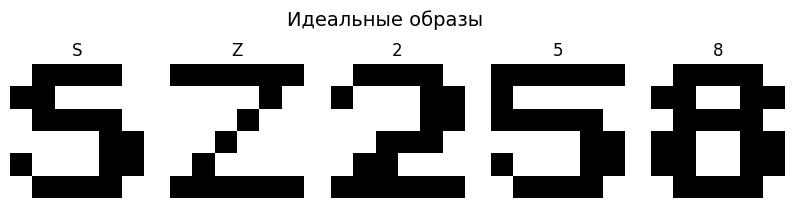

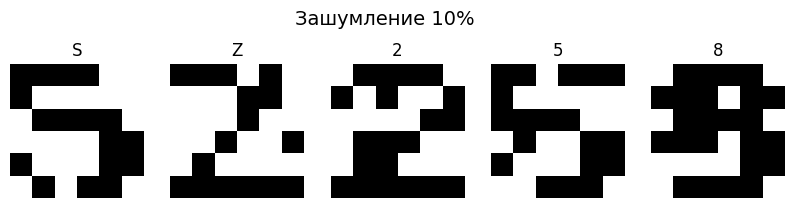

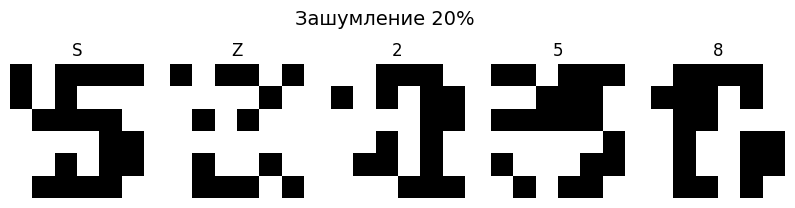

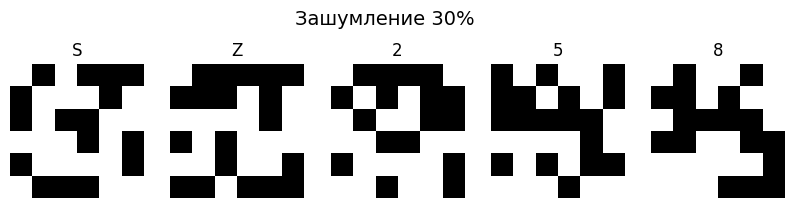

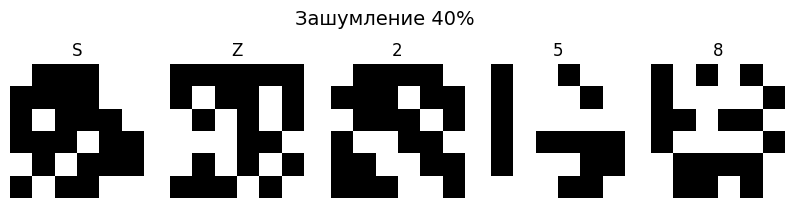

In [15]:
noise_levels = {
    "0%": 0,
    "10%": 4,
    "20%": 7,
    "30%": 11,
    "40%": 14
}

all_images = {}
for noise_name, flips in noise_levels.items():
    all_images[noise_name] = {}
    for label, img in base_images.items():
        if flips == 0:
            all_images[noise_name][label] = img.copy()
        else:
            all_images[noise_name][label] = add_noise(img, flips)

show_images(base_images, "Идеальные образы")
show_images(all_images["10%"], "Зашумление 10%")
show_images(all_images["20%"], "Зашумление 20%")
show_images(all_images["30%"], "Зашумление 30%")
show_images(all_images["40%"], "Зашумление 40%")


## 4. Обучающая выборка

Сеть получает только пять идеальных нормированных векторов.


In [16]:
labels = list(base_images.keys())
X_train = np.array([normalize_vector(to_vector(base_images[label])) for label in labels])
print('Порядок образов:', ', '.join(labels))
print('Форма X_train:', X_train.shape)
print('Длины векторов:', np.linalg.norm(X_train, axis=1))
assert X_train.shape == (5, 36)
assert np.allclose(np.linalg.norm(X_train, axis=1), 1)


Порядок образов: S, Z, 2, 5, 8
Форма X_train: (5, 36)
Длины векторов: [1. 1. 1. 1. 1.]


## 5. Обучение конкурентной сети

Веса имеют форму (36, m). Победитель минимизирует $KRIT_j=f_j\|x-W_j\|$. Счётчики начинаются с 1, чтобы критерий не обнулился для всех нейронов. После победы счётчик увеличивается, а веса корректируются: $W_j\leftarrow W_j+h(x-W_j)$ и снова нормируются, как в теории и примере однокурсницы.

В каждом опыте выполняются 30 эпох, то есть 150 предъявлений образов.


In [17]:
def train_competitive_network(X, m=5, h=0.05, epochs=30, seed=37):
    np.random.seed(seed)
    n = X.shape[1]  # Размерность входного вектора (36)

    # Инициализация весов случайными значениями от -1 до 1 и нормировка
    W = np.random.rand(n, m) * 2 - 1
    for j in range(m):
        W[:, j] = normalize_vector(W[:, j])

    # Фактор "совести" (частота побед)
    f = np.ones(m)

    for _ in range(epochs):
        for x in X:
            # Критерий KRIT_j = f_j * ||X - W_j||
            krit = np.array([np.linalg.norm(x - W[:, j]) * f[j] for j in range(m)])

            # Нейрон-победитель: минимальный критерий
            winner = int(np.argmin(krit))

            # Увеличение счетчика побед
            f[winner] += 1

            # Коррекция весов победителя (правило Кохонена) и нормировка
            W[:, winner] = W[:, winner] + h * (x - W[:, winner])
            W[:, winner] = normalize_vector(W[:, winner])

    return W, f


## 6. Определение кластеров и оценка результатов

В таблицах строки соответствуют S, Z, 2, 5, 8, столбцы — уровням шума. Число в ячейке — номер кластера. Сравниваем два показателя: число разных кластеров идеальных образов и число зашумлённых версий, сохранивших кластер своего идеала (из 20). Сохранение кластера само по себе не означает распознавание символа, если несколько идеалов объединены в один кластер.


In [18]:
def predict_cluster(x, W, f):
    x = normalize_vector(x)
    krit = np.array([np.linalg.norm(x - W[:, j]) * f[j] for j in range(W.shape[1])])
    return int(np.argmin(krit)) + 1  # Номер кластера (с 1)

def evaluate_network(all_images, W, f):
    levels = ["0%", "10%", "20%", "30%", "40%"]
    result = np.zeros((len(labels), len(levels)), dtype=int)
    for i, label in enumerate(labels):
        for j, level in enumerate(levels):
            x = to_vector(all_images[level][label])
            result[i, j] = predict_cluster(x, W, f)
    return result


def show_result(result, m, h):
    print('Строки:', ', '.join(labels))
    print('Столбцы: 0%, 10%, 20%, 30%, 40%')
    print(result)
    assert result.shape == (5, 5)
    assert np.all((result >= 1) & (result <= m))
    fig, ax = plt.subplots(figsize=(6.5, 2.6))
    ax.axis('off')
    table = ax.table(cellText=result, rowLabels=labels,
                     colLabels=['0%', '10%', '20%', '30%', '40%'],
                     cellLoc='center', rowLoc='center', loc='center')
    table.auto_set_font_size(False)
    table.set_fontsize(12)
    table.scale(1, 1.6)
    palette = ['#deebf7', '#e2f0d9', '#fff2cc', '#fce4d6', '#e4dfec']
    for i in range(5):
        for j in range(5):
            table[i + 1, j].set_facecolor(palette[result[i, j] - 1])
    ax.set_title(f'Кластеры: m={m}, h={h}', pad=12)
    plt.tight_layout()
    plt.show()

experiments = {}


## 7. Эксперимент 1: m=5, h=0.05

Меняем число кластеров при одинаковой скорости обучения.

Строки: S, Z, 2, 5, 8
Столбцы: 0%, 10%, 20%, 30%, 40%
[[1 5 2 5 5]
 [4 4 5 5 5]
 [3 3 5 5 5]
 [2 5 5 5 5]
 [1 2 5 5 5]]


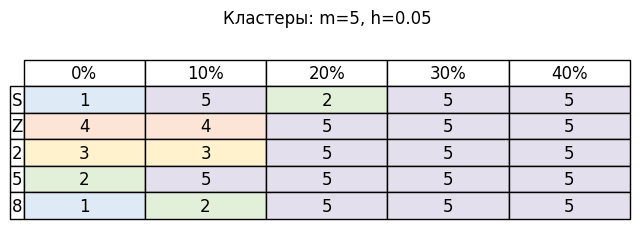

In [19]:
W1, f1 = train_competitive_network(X_train, m=5, h=0.05, epochs=30, seed=37)
REZ1 = evaluate_network(all_images, W1, f1)
show_result(REZ1, m=5, h=0.05)
assert np.allclose(np.linalg.norm(W1, axis=0), 1)
assert f1.sum() == 5 + 30 * len(labels)
experiments[(5, 0.05)] = REZ1


## 8. Эксперимент 2: m=4, h=0.05

Меняем число кластеров при одинаковой скорости обучения.

Строки: S, Z, 2, 5, 8
Столбцы: 0%, 10%, 20%, 30%, 40%
[[1 1 2 2 2]
 [4 4 4 3 3]
 [3 3 3 3 2]
 [1 2 2 2 2]
 [2 2 2 2 2]]


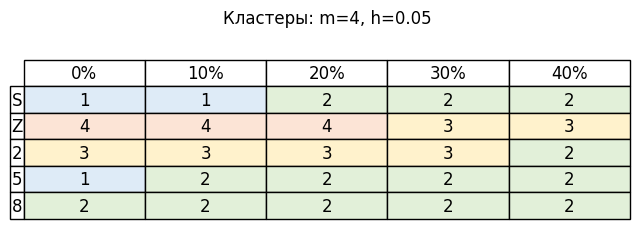

In [20]:
W2, f2 = train_competitive_network(X_train, m=4, h=0.05, epochs=30, seed=37)
REZ2 = evaluate_network(all_images, W2, f2)
show_result(REZ2, m=4, h=0.05)
assert np.allclose(np.linalg.norm(W2, axis=0), 1)
assert f2.sum() == 4 + 30 * len(labels)
experiments[(4, 0.05)] = REZ2


## 9. Эксперимент 3: m=3, h=0.05

Меняем число кластеров при одинаковой скорости обучения.

Строки: S, Z, 2, 5, 8
Столбцы: 0%, 10%, 20%, 30%, 40%
[[3 2 2 2 2]
 [1 2 2 2 2]
 [1 1 2 2 2]
 [2 2 2 2 2]
 [3 2 2 2 2]]


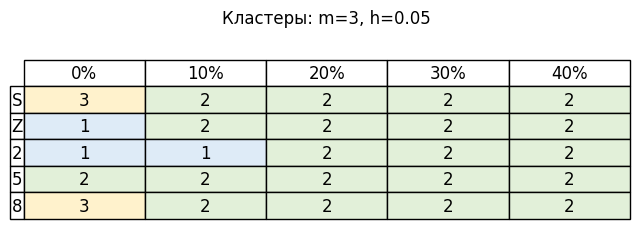

In [21]:
W3, f3 = train_competitive_network(X_train, m=3, h=0.05, epochs=30, seed=37)
REZ3 = evaluate_network(all_images, W3, f3)
show_result(REZ3, m=3, h=0.05)
assert np.allclose(np.linalg.norm(W3, axis=0), 1)
assert f3.sum() == 3 + 30 * len(labels)
experiments[(3, 0.05)] = REZ3


## 10. Эксперимент 4: m=5, h=0.01

Сравниваем скорость обучения при пяти выходных нейронах.

Строки: S, Z, 2, 5, 8
Столбцы: 0%, 10%, 20%, 30%, 40%
[[2 5 2 2 2]
 [1 2 2 1 5]
 [3 1 3 5 5]
 [2 5 2 5 5]
 [4 2 1 4 3]]


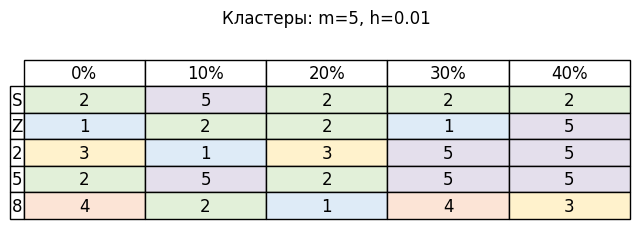

In [22]:
W4, f4 = train_competitive_network(X_train, m=5, h=0.01, epochs=30, seed=37)
REZ4 = evaluate_network(all_images, W4, f4)
show_result(REZ4, m=5, h=0.01)
assert np.allclose(np.linalg.norm(W4, axis=0), 1)
assert f4.sum() == 5 + 30 * len(labels)
experiments[(5, 0.01)] = REZ4


## 11. Эксперимент 5: m=5, h=0.1

Сравниваем скорость обучения при пяти выходных нейронах.

Строки: S, Z, 2, 5, 8
Столбцы: 0%, 10%, 20%, 30%, 40%
[[1 2 2 5 5]
 [4 4 5 5 5]
 [3 3 3 5 5]
 [2 2 2 5 5]
 [5 5 5 5 5]]


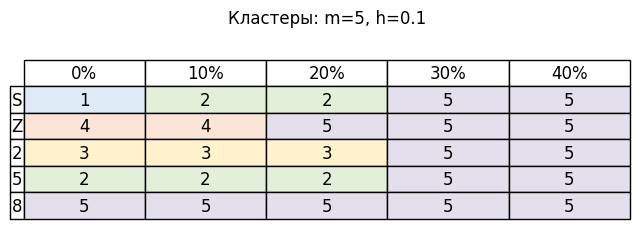

In [23]:
W5, f5 = train_competitive_network(X_train, m=5, h=0.1, epochs=30, seed=37)
REZ5 = evaluate_network(all_images, W5, f5)
show_result(REZ5, m=5, h=0.1)
assert np.allclose(np.linalg.norm(W5, axis=0), 1)
assert f5.sum() == 5 + 30 * len(labels)
experiments[(5, 0.1)] = REZ5


## 12. Сравнение результатов


In [24]:
print(' m |    h | Кластеров у идеалов | Сохранено из 20 | По шумам 10/20/30/40%')
for (m, h), result in experiments.items():
    unique = np.unique(result[:, 0]).size
    retained = result[:, 1:] == result[:, [0]]
    print(f'{m:2d} | {h:4.2f} | {unique:19d} | {retained.sum():15d} | {retained.sum(axis=0)}')


 m |    h | Кластеров у идеалов | Сохранено из 20 | По шумам 10/20/30/40%
 5 | 0.05 |                   4 |               2 | [2 0 0 0]
 4 | 0.05 |                   4 |              10 | [4 3 2 1]
 3 | 0.05 |                   3 |               5 | [2 1 1 1]
 5 | 0.01 |                   4 |               7 | [0 3 3 1]
 5 | 0.10 |                   5 |               9 | [4 3 1 1]


## 13. Выводы по выполненным опытам

| m | h | Разных кластеров у идеалов | Сохранили кластер идеала |
|---|---|---|---|
| 5 | 0.05 | 4 из 5 | 2 из 20 |
| 4 | 0.05 | 4 из 5 | 10 из 20 |
| 3 | 0.05 | 3 из 5 | 5 из 20 |
| 5 | 0.01 | 4 из 5 | 7 из 20 |
| 5 | 0.1 | 5 из 5 | 9 из 20 |

**Влияние числа нейронов.** При h=0,05 получены следующие группы идеальных образов:
- m=5: кластер 1: S, 8; кластер 2: 5; кластер 3: 2; кластер 4: Z.
- m=4: кластер 1: S, 5; кластер 2: 8; кластер 3: 2; кластер 4: Z.
- m=3: кластер 1: Z, 2; кластер 2: 5; кластер 3: S, 8.

**Влияние скорости обучения.** В данном наборе при m=5 больше всего искажённых образов сохранили кластер идеала при h=0,1: 9 из 20. Этот показатель нужно читать вместе с числом разных кластеров идеалов: совпадение кластера не доказывает различение символов.

**Общий вывод.** Сеть выполнила группировку образов S, Z, 2, 5, 8. Матрицы показывают, какие искажения меняют кластер и какие идеальные символы объединяются. При m<5 отдельного кластера для каждого из пяти символов быть не может. Выводы относятся к заданным растрам, одному набору шума, seed=37 и 30 эпохам; они не доказывают превосходство параметра для любых данных или достижение сходимости.

## 14. Контрольные вопросы

**1. В чём смысл самообучения?** Сеть изменяет веса по входным данным, не получая готовых целевых ответов, и группирует похожие образы.

**2. Как обучается конкурентная сеть?** Входы и начальные веса нормируются. Для каждого образа вычисляются критерии нейронов, выбирается победитель, увеличивается его счётчик и изменяются только его веса. Эти действия повторяются по эпохам.

**3. Как определяется нейрон-победитель?** В данной работе выбирается минимум произведения расстояния до весового вектора и счётчика побед. Большой счётчик снижает преимущество часто побеждающего нейрона при прочих равных условиях.

**4. Где применяются самоорганизующиеся сети?** Для кластеризации данных, выделения признаков и сжатия представления данных.

**5. Достоинства и недостатки?** Не нужны целевые ответы для обучения, а группы можно анализировать по победителям. Результат зависит от числа кластеров, скорости обучения, инициализации и порядка предъявления данных. Устойчивость к шуму требуется проверять экспериментально.
